In [34]:
from schedule import Schedule, Slot

No conflicts detected.

Compiled Transmission Windows:
Queue 1, start 0, end 110, streams [1, 2, 3, 4]
Queue 1, start 200, end 285, streams [1, 2]
Queue 1, start 300, end 310, streams [1]
Queue 2, start 385, end 390, streams [3]
Queue 1, start 400, end 485, streams [1, 2]


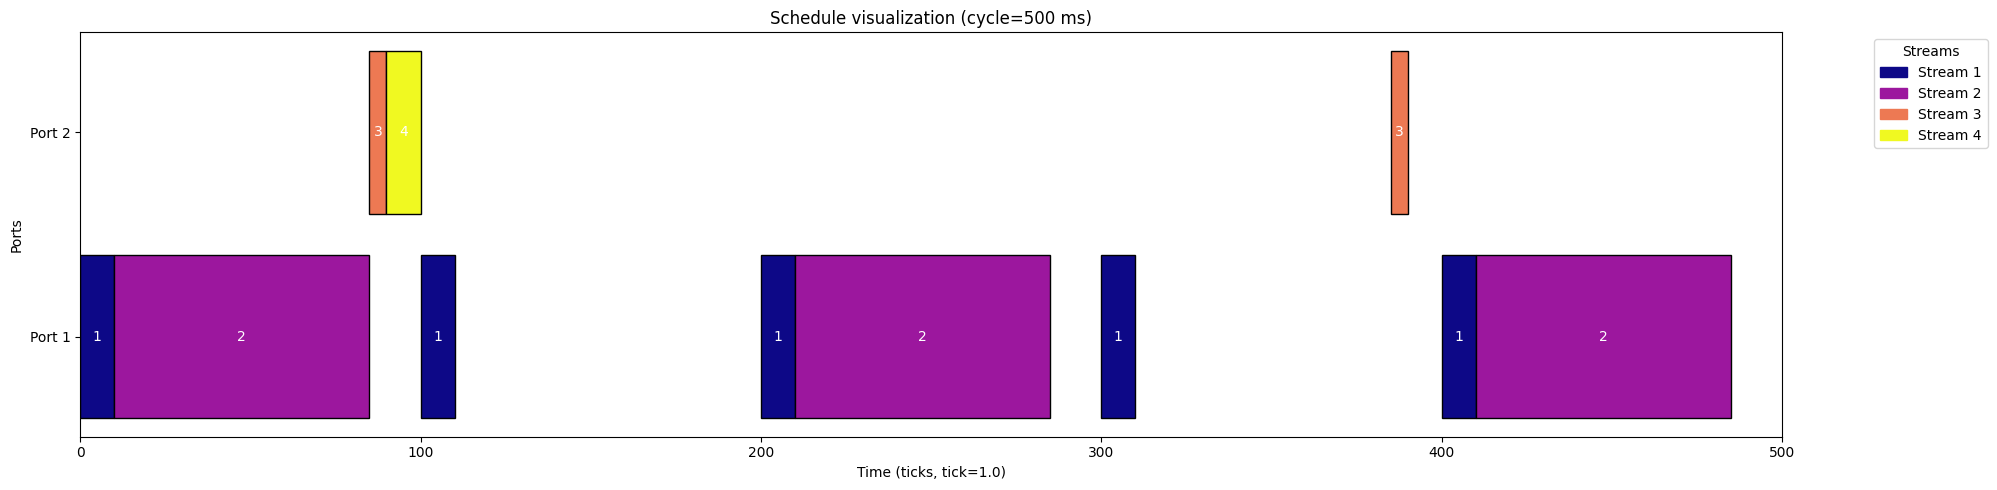

In [26]:
import matplotlib.pyplot as plt

# Create schedule with cycle 500 ms
sched = Schedule(cycle_ms=500)

# Queue 1 streams (no overlap)
sched.append(Slot(start_ms=0, end_ms=10, period_ms=100, queue_id=1, stream_id=1))
sched.append(Slot(start_ms=10, end_ms=85, period_ms=200, queue_id=1, stream_id=2))

# Queue 2 streams (no overlap)
sched.append(Slot(start_ms=85, end_ms=90, period_ms=300, queue_id=2, stream_id=3))
sched.append(Slot(start_ms=90, end_ms=100, period_ms=600, queue_id=2, stream_id=4))

# Validate conflicts
conflicts = sched.validate_conflicts()
if conflicts:
    print("Conflicts detected:")
    for s1, s2 in conflicts:
        print(f"Slot {s1.index} ({s1.stream_id}) conflicts with Slot {s2.index} ({s2.stream_id})")
else:
    print("No conflicts detected.")

# Compile schedule
compiled = sched.compile()
print("\nCompiled Transmission Windows:")
for w in compiled:
    print(f"Queue {w.queue_id}, start {w.start_ms}, end {w.end_ms}, streams {w.stream_sequence}")

# Plot schedule
fig = sched.plot(tick=1.0)
plt.show()

In [24]:
sched.utilization

0.59

In [35]:
from tsn_scheduling_problem import TSNScheduling

problem = TSNScheduling("uc_config.cfg")

instance = problem.instantiate()

filepath = "test.json"
instance1 = problem.import_scheduling_usecase(filepath)

In [38]:
instance.streams

[{'name': 'stream-0',
  'type': 'isochronous',
  'interval': 100000,
  'maxFramesPerInterval': 1,
  'maxFrameSize': 166,
  'maxLatency': 10000000,
  'tlkrPssblPlcmnt': ['host-6-p1'],
  'lstnsrPssblPlcmnt': [['host-2-p0']],
  'earliest-transmit-offset': 0,
  'latest-transmit-offset': 50000,
  'jitter': 0,
  'lifespanCycles': 7330000,
  'pathLists': [['host-6-p1.Port1',
    'switch-p1-e1.Port1',
    'switch-p1-a1.Port3',
    'switch-c1.Port1',
    'switch-p0-a1.Port1',
    'switch-p0-e1.Port4',
    'host-2-p0']]},
 {'name': 'stream-1',
  'type': 'isochronous',
  'interval': 100000,
  'maxFramesPerInterval': 1,
  'maxFrameSize': 118,
  'maxLatency': 10000000,
  'tlkrPssblPlcmnt': ['host-15-p3'],
  'lstnsrPssblPlcmnt': [['host-14-p3']],
  'earliest-transmit-offset': 0,
  'latest-transmit-offset': 50000,
  'jitter': 0,
  'lifespanCycles': 7870000,
  'pathLists': [['host-15-p3.Port1',
    'switch-p3-e2.Port1',
    'switch-p3-a1.Port1',
    'switch-p3-e1.Port4',
    'host-14-p3']]},
 {'name':

## TSN Defragmentation Environment Test

In [40]:
# Reload the env module to get latest changes
import importlib
import env
importlib.reload(env)
from env import TSNDefragEnv
import numpy as np

# Create environment
env_obj = TSNDefragEnv(
    problem=problem,
    usecase=instance1,
    gap_threshold_ms=5.0,
    move_penalty=0.01
)

# Reset with empty schedules (no auto-population)
state = env_obj.reset(auto_populate=False)

print(f"Environment has {env_obj.n_streams} streams and {env_obj.n_ports} ports")

# Manually add slots - use stream IDs 0 and 1 (instance1 has only 2 streams)
# Port 1 streams
env_obj.add_slot(1, Slot(start_ms=0, end_ms=10, period_ms=100, queue_id=1, stream_id=0))
env_obj.add_slot(1, Slot(start_ms=10, end_ms=85, period_ms=200, queue_id=1, stream_id=1))

# Port 2 streams - reuse stream IDs 0 and 1 on different port
env_obj.add_slot(2, Slot(start_ms=85, end_ms=90, period_ms=300, queue_id=2, stream_id=0))
env_obj.add_slot(2, Slot(start_ms=90, end_ms=100, period_ms=600, queue_id=2, stream_id=1))

# Get state after manual population
state = env_obj._get_state()

print("\nState keys:", state.keys())
print("Stream placement shape:", state['stream_placement'].shape)
print("Stream features shape:", state['stream_features'].shape)
print("Port metrics shape:", state['port_metrics'].shape)
print("Adjacency matrix shape:", state['adjacency_matrix'].shape)

# Get environment info
info = env_obj.get_info()
print("\nEnvironment Info:")
print(f"  Total gaps: {info['total_gaps']}")

print("\nPort utilizations:")
for port_id, util in info['port_utilizations'].items():
    if util > 0:  # Only show ports with utilization
        print(f"  Port {port_id}: {util:.2%}")

Environment has 2 streams and 36 ports

State keys: dict_keys(['stream_placement', 'stream_features', 'port_metrics', 'adjacency_matrix'])
Stream placement shape: (2, 36)
Stream features shape: (2, 6)
Port metrics shape: (36, 4)
Adjacency matrix shape: (2, 36)

Environment Info:
  Total gaps: 2702

Port utilizations:
  Port 1: 47.50%
  Port 2: 3.34%


In [41]:
# Test taking a step with an action
# Action shape: (N_streams x N_ports)
# Each entry is the new start time offset in ms

# Create an action: shift stream 1 on port 1 slightly
action = np.zeros((env_obj.n_streams, env_obj.n_ports))

# Example: move stream 1 (currently at 10ms) to 15ms on port 1
action[1, 0] = 15  # stream_id=1, port_id=1 (0-indexed in action matrix)

# Take step
next_state, reward, done, step_info = env_obj.step(action)

print("Step Results:")
print(f"  Reward: {reward:.4f}")
print(f"  Delta fragmentation: {step_info['delta_fragmentation']:.4f}")
print(f"  Moves made: {step_info['n_moves']}")
print(f"  Total gaps before: {env_obj.previous_gaps}")
print(f"  Total gaps after: {step_info['total_gaps']}")
print(f"  Done: {done}")

# Visualize port 1 schedule
print("\n=== Port 1 Schedule ===")
for slot in env_obj.schedules[1]:
    print(f"  Stream {slot.stream_id}: [{slot.start_ms:.1f}, {slot.end_ms:.1f}] ms")

Step Results:
  Reward: -101.8356
  Delta fragmentation: -101.8056
  Moves made: 3
  Total gaps before: 3701
  Total gaps after: 3701
  Done: False

=== Port 1 Schedule ===
  Stream 0: [0.0, 10.0] ms
  Stream 1: [15.0, 90.0] ms


### Environment Key Features

**State Encoding:**
- `stream_placement` (N×P): Normalized offset position for each stream on each port
- `stream_features` (N×6): offset, duration, period, latency, hop_cost, extra
- `port_metrics` (P×4): utilization, useless_gaps_ratio, avg_useful_gap, total_gaps
- `adjacency_matrix` (2×E): Line graph of port connections

**Action:**
- N×P matrix where `action[i,j]` = new start time (ms) for stream i on port j

**Reward:**
- `R = Δfragmentation - move_penalty × n_moves`
- `Δfragmentation = (gaps_old - gaps_new) / max(1, gaps_old)`

### Alternative: Use set_schedules() to initialize all at once

In [42]:
# Alternative approach: create schedules manually, then set them
from schedule import Schedule, Slot

# Create schedules for each port (using stream IDs 0 and 1)
schedule_port1 = Schedule(cycle_ms=500, port_id=1)
schedule_port1.append(Slot(start_ms=0, end_ms=10, period_ms=100, queue_id=1, stream_id=0))
schedule_port1.append(Slot(start_ms=10, end_ms=85, period_ms=200, queue_id=1, stream_id=1))

schedule_port2 = Schedule(cycle_ms=500, port_id=2)
schedule_port2.append(Slot(start_ms=85, end_ms=90, period_ms=300, queue_id=2, stream_id=0))
schedule_port2.append(Slot(start_ms=90, end_ms=100, period_ms=600, queue_id=2, stream_id=1))

# Create new environment
env2 = TSNDefragEnv(
    problem=problem,
    usecase=instance1,
    gap_threshold_ms=5.0,
    move_penalty=0.01
)

# Reset and set schedules
env2.reset(auto_populate=False)
env2.set_schedules({1: schedule_port1, 2: schedule_port2})

# Get state
state2 = env2._get_state()
info2 = env2.get_info()

print("Environment initialized with set_schedules:")
print(f"  Total gaps: {info2['total_gaps']}")
print(f"  Port 1 utilization: {info2['port_utilizations'][1]:.2%}")
print(f"  Port 2 utilization: {info2['port_utilizations'][2]:.2%}")

Environment initialized with set_schedules:
  Total gaps: 8
  Port 1 utilization: 55.00%
  Port 2 utilization: 4.00%
